In [60]:
!pip install pingouin factor_analyzer -q

In [61]:
!pip install --upgrade numpy scipy pingouin factor_analyzer

In [62]:
import pandas as pd, numpy as np, pingouin as pg
from scipy import stats
from factor_analyzer import FactorAnalyzer, calculate_kmo, calculate_bartlett_sphericity

In [63]:
from google.colab import files
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses 3 TIC).xlsx to Blank Quiz (Responses 3 TIC) (4).xlsx
File terbaca: Blank Quiz (Responses 3 TIC) (4).xlsx


# Membaca data dan memisahkan Butir

In [64]:
JUMLAH_KOLOM_DEMOGRAFI = 5
df = pd.read_excel(nama_file)

# Rapikan nama kolom dari spasi berlebih
df.columns = df.columns.astype(str).str.strip()

# Filter hanya kelas 3 TI C
df = df[df['Kelas'].astype(str).str.strip().str.upper() == '3 TI C'].reset_index(drop=True)

# Ambil hanya kolom butir Likert (berformat "Dimensi [butir]"), setelah kolom demografi
kolom_butir = [k for k in df.columns[JUMLAH_KOLOM_DEMOGRAFI:] if "[" in k]
butir = df[kolom_butir]

# Rapikan spasi pada jawaban teks
butir = butir.apply(lambda c: c.str.strip() if c.dtype == "object" else c)

print("Jumlah responden :", len(df))
print("Jumlah butir :", butir.shape[1])
print("Data kosong :", int(butir.isna().sum().sum()))

# Kolom yang dibuang (bukan butir Likert), untuk pengecekan
dibuang = [k for k in df.columns[JUMLAH_KOLOM_DEMOGRAFI:] if "[" not in k]
print("Kolom non-butir yang dilewati:", dibuang)

Jumlah responden : 40
Jumlah butir : 29
Data kosong : 0
Kolom non-butir yang dilewati: ['Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai dengan hiburan']


# Mengubah Jawaban Likert menjadi Angka

In [65]:
skala = {
"Sangat Tidak Setuju (STJ)": 1,
"Tidak Setuju (TS)": 2,
"Netral (N)": 3,
"Setuju (S)": 4,
"Sangat Setuju (SS)": 5,
}
num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")
# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Respon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,5,5,4,4,4,4,4,5,4,4,...,2,5,4,5,4,5,5,4,4,5
1,4,4,4,4,4,4,4,5,4,4,...,4,2,4,4,4,5,4,5,5,5
2,5,5,4,4,4,4,4,4,4,4,...,2,4,5,4,2,5,5,5,4,5
3,5,4,5,2,4,5,5,4,4,2,...,2,4,4,4,4,5,4,4,4,4
4,5,5,4,4,5,5,5,4,2,4,...,2,2,2,2,4,5,5,4,5,5


In [66]:
print("Data kosong asli      :", int(butir.isna().sum().sum()))

gagal = num.isna() & butir.notna()
print("Gagal karena teks lain:", int(gagal.sum().sum()))

# Lihat teks apa saja yang tidak terbaca
print(butir[gagal].stack().value_counts())

Data kosong asli      : 0
Gagal karena teks lain: 0
Series([], Name: count, dtype: int64)


# Mengelompokkan Butir per Dimensi

In [68]:
import re

dimensi = {}
for kolom in butir.columns:
    cocok = re.match(r"^(.*?)\s*\[", str(kolom))
    if cocok is None:
        print(f"Dilewati (bukan butir berformat 'Dimensi [butir]'): {kolom}")
        continue
    # rapikan spasi ganda dan titik di akhir nama dimensi
    nama = re.sub(r"\s+", " ", cocok.group(1)).strip().rstrip(".").strip()
    dimensi.setdefault(nama, []).append(kolom)

print("Jumlah dimensi:", len(dimensi), "\n")
for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Jumlah dimensi: 5 

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respon emosional: 5 butir


# UJI VALIDITAS

In [69]:
hasil_validitas = []

for nama, daftar in dimensi.items():
    # Data dimensi ini; baris dengan jawaban kosong dibuang (listwise)
    x = num[daftar].dropna()
    n = len(x)

    # r tabel dihitung per dimensi karena n bisa berbeda setelah baris kosong dibuang
    t = stats.t.ppf(0.975, n - 2)
    r_tabel = t / np.sqrt((n - 2) + t**2)
    print(f"{nama}: n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

    total = x.sum(axis=1)

    for i, kolom in enumerate(daftar, 1):
        # Lewati butir yang jawabannya seragam semua (korelasi tidak bisa dihitung)
        if x[kolom].nunique() < 2:
            hasil_validitas.append({
                "Dimensi": nama, "Butir": f"B{i}", "n": n,
                "r hitung": np.nan, "Corrected r": np.nan,
                "r tabel": round(r_tabel, 3), "p-value": np.nan,
                "Keterangan": "Tidak dapat dihitung (tidak ada variasi)",
            })
            continue

        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])

        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "n": n,
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "r tabel": round(r_tabel, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

Penggunaan AI pada tugas atau projek kuliah: n = 40 | r tabel (α=0,05; df=38) = 0.312
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: n = 40 | r tabel (α=0,05; df=38) = 0.312
Kebiasaan penggunaan teknologi digital: n = 40 | r tabel (α=0,05; df=38) = 0.312
Prokrastinasi akademik: n = 40 | r tabel (α=0,05; df=38) = 0.312
Respon emosional: n = 40 | r tabel (α=0,05; df=38) = 0.312


,Dimensi,Butir,n,r hitung,Corrected r,r tabel,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,40,0.419,0.222,0.312,0.0071,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,40,0.390,0.224,0.312,0.0129,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,40,0.626,0.418,0.312,0.0000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,40,0.506,0.205,0.312,0.0009,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,40,0.793,0.597,0.312,0.0000,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,40,0.634,0.424,0.312,0.0000,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,40,0.231,-0.061,0.312,0.1510,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,40,0.578,0.437,0.312,0.0001,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,40,0.708,0.541,0.312,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,40,0.804,0.651,0.312,0.0000,Valid


# UJI REALIBILITAS

In [70]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else
            "Baik" if a >= 0.80 else
            "Reliabel" if a >= 0.70 else
            "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar].dropna()          # buang responden dengan jawaban kosong
    a = cronbach_alpha(x)

    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "n": len(x),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })

    # alpha jika butir dihapus hanya bermakna jika butir > 2
    if len(daftar) > 2:
        for i, kolom in enumerate(daftar, 1):
            a_hapus = cronbach_alpha(x.drop(columns=kolom))
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha dimensi": round(a, 3),
                "Alpha jika dihapus": round(a_hapus, 3),
                "Selisih": round(a_hapus - a, 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)

# Gabungkan dengan hasil validitas agar keputusan hapus butir lebih kuat
tabel_alpha_dihapus = tabel_alpha_dihapus.merge(
    tabel_validitas[["Dimensi", "Butir", "Corrected r", "Keterangan"]],
    on=["Dimensi", "Butir"], how="left"
).rename(columns={"Keterangan": "Validitas"})

def saran(row):
    naik = row["Selisih"] > 0
    tdk_valid = row["Validitas"] != "Valid"
    if naik and tdk_valid:
        return "Disarankan dihapus"
    if naik:
        return "Pertimbangkan (alpha naik)"
    return "Pertahankan"

tabel_alpha_dihapus["Saran"] = tabel_alpha_dihapus.apply(saran, axis=1)

display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

# Ringkasan butir yang bermasalah
bermasalah = tabel_alpha_dihapus[tabel_alpha_dihapus["Saran"] != "Pertahankan"]
print("\nButir yang perlu diperhatikan:")
display(bermasalah if len(bermasalah) else "Tidak ada, semua butir sebaiknya dipertahankan.")

,Dimensi,Jumlah butir,n,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,40,0.550,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,40,0.678,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,40,0.808,Baik
3,Prokrastinasi akademik,4,40,0.865,Baik
4,Respon emosional,5,40,0.555,Tidak reliabel


,Dimensi,Butir,Alpha dimensi,Alpha jika dihapus,Selisih,Corrected r,Validitas,Saran
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.550,0.531,-0.019,0.222,Valid,Pertahankan
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.550,0.533,-0.018,0.224,Valid,Pertahankan
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.550,0.456,-0.095,0.418,Valid,Pertahankan
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.550,0.547,-0.003,0.205,Valid,Pertahankan
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.550,0.341,-0.209,0.597,Valid,Pertahankan
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.550,0.453,-0.098,0.424,Valid,Pertahankan
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.550,0.639,0.089,-0.061,Tidak valid,Disarankan dihapus
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.678,0.637,-0.041,0.437,Valid,Pertahankan
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.678,0.597,-0.081,0.541,Valid,Pertahankan
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.678,0.550,-0.128,0.651,Valid,Pertahankan



Butir yang perlu diperhatikan:


,Dimensi,Butir,Alpha dimensi,Alpha jika dihapus,Selisih,Corrected r,Validitas,Saran
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.550,0.639,0.089,-0.061,Tidak valid,Disarankan dihapus
12,Aspek Psikologis penggunaan AI pada tugas atau...,B6,0.678,0.684,0.006,0.208,Valid,Pertimbangkan (alpha naik)
13,Aspek Psikologis penggunaan AI pada tugas atau...,B7,0.678,0.769,0.091,-0.272,Tidak valid,Disarankan dihapus
14,Kebiasaan penggunaan teknologi digital,B1,0.808,0.812,0.004,0.392,Valid,Pertimbangkan (alpha naik)
23,Prokrastinasi akademik,B4,0.865,0.886,0.021,0.569,Valid,Pertimbangkan (alpha naik)
27,Respon emosional,B4,0.555,0.644,0.088,0.065,Valid,Pertimbangkan (alpha naik)


In [85]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"],
how="left")
with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
  gabung.to_excel(w, sheet_name="Validitas", index=False)
  tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Visualisasi Distribusi Data

,Dimensi,Jumlah butir,Rata-rata,Median,Std. deviasi,Min,Maks,% Tidak setuju (1-2),% Netral (3),% Setuju (4-5),Kategori rata-rata
0,Penggunaan AI pada tugas atau projek kuliah,7,4.150,4.286,0.428,3.43,5.00,8.6,2.1,89.3,Tinggi
1,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,7,3.636,3.643,0.638,2.29,4.71,26.4,4.3,69.3,Tinggi
2,Kebiasaan penggunaan teknologi digital,6,3.375,3.500,0.887,1.83,5.00,37.9,2.1,60.0,Sedang
3,Prokrastinasi akademik,4,3.262,3.500,1.117,1.50,5.00,40.6,2.5,56.9,Sedang
4,Respon emosional,5,4.080,4.200,0.576,2.40,4.80,11.5,2.0,86.5,Tinggi


,Dimensi,Butir,Rata-rata,Std. deviasi,Median,% Setuju (4-5)
0,Penggunaan AI pada tugas atau projek kuliah,B1,4.425,0.636,4.0,97.5
1,Penggunaan AI pada tugas atau projek kuliah,B2,4.350,0.533,4.0,97.5
2,Penggunaan AI pada tugas atau projek kuliah,B3,4.225,0.800,4.0,92.5
3,Penggunaan AI pada tugas atau projek kuliah,B4,3.650,0.975,4.0,77.5
4,Penggunaan AI pada tugas atau projek kuliah,B5,3.875,1.017,4.0,77.5
5,Penggunaan AI pada tugas atau projek kuliah,B6,4.275,0.816,4.0,92.5
6,Penggunaan AI pada tugas atau projek kuliah,B7,4.250,0.870,4.0,90.0
7,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B1,4.175,0.813,4.0,90.0
8,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B2,3.525,1.132,4.0,65.0
9,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B3,2.850,1.312,2.0,42.5


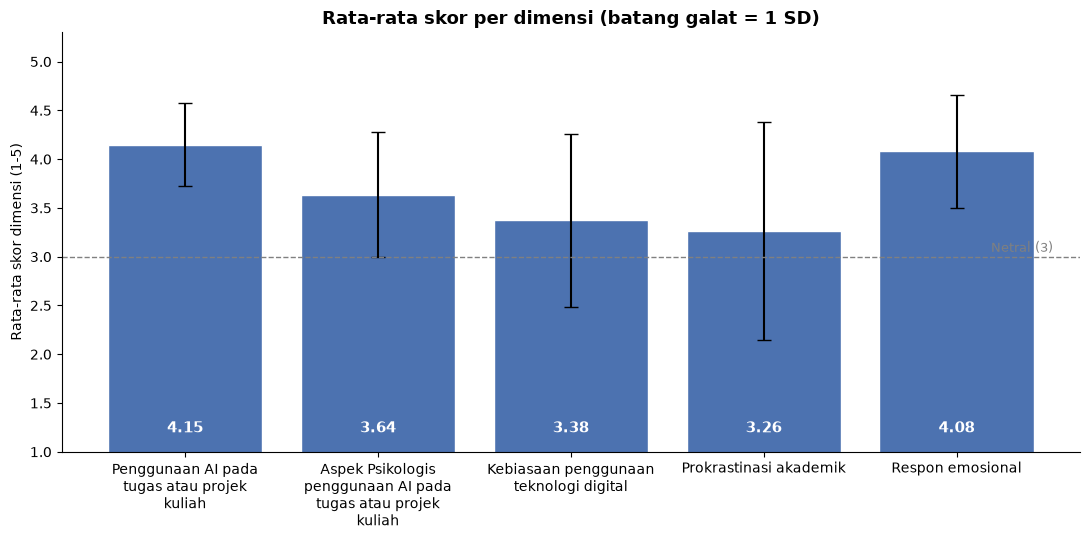

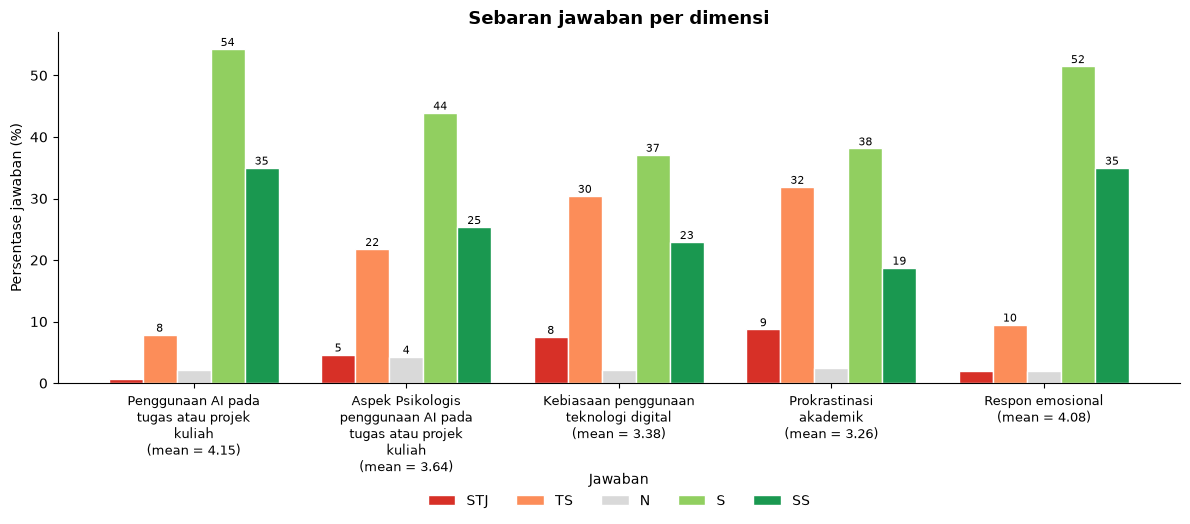

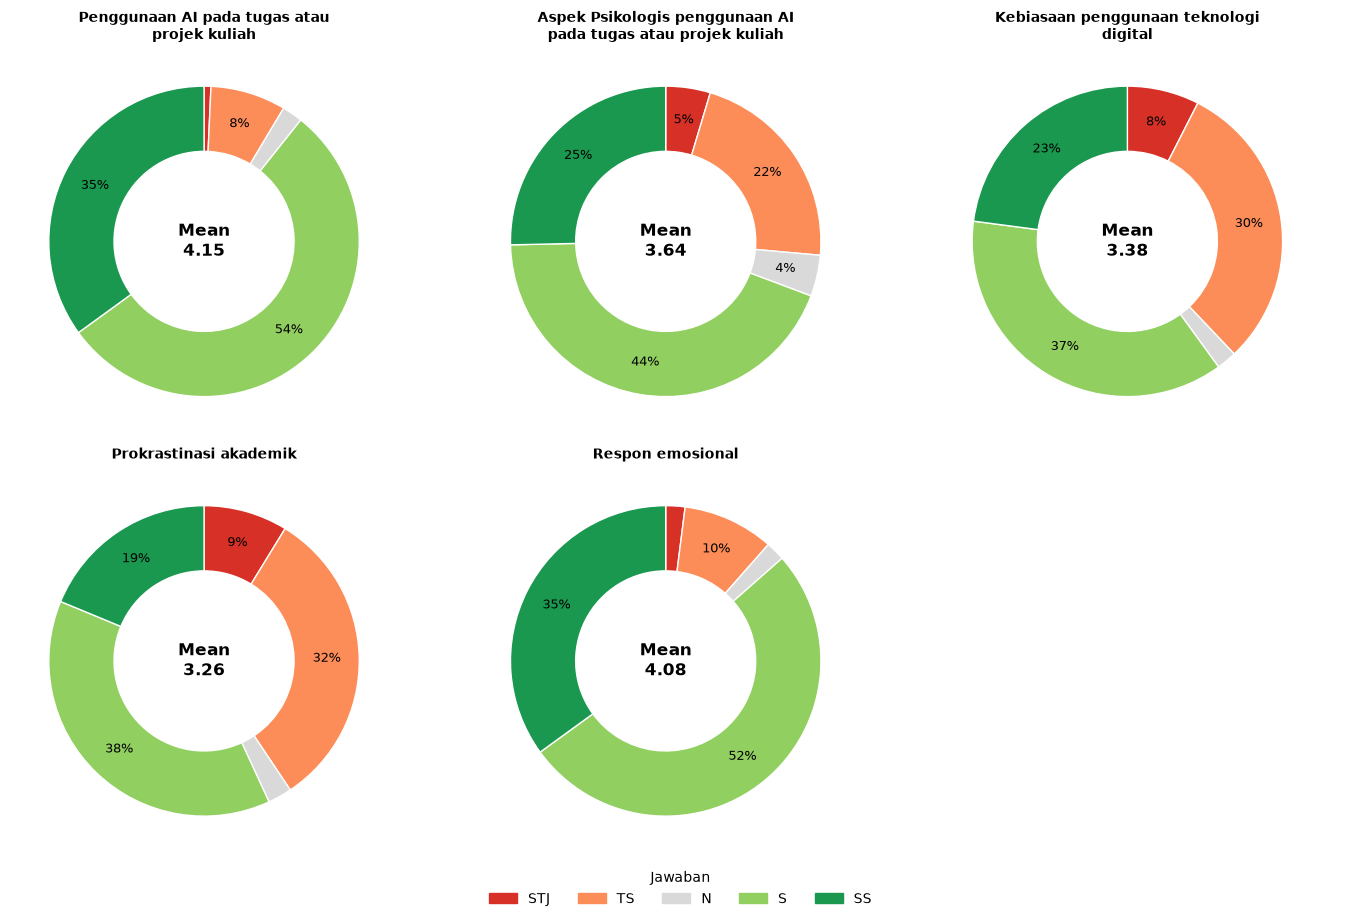

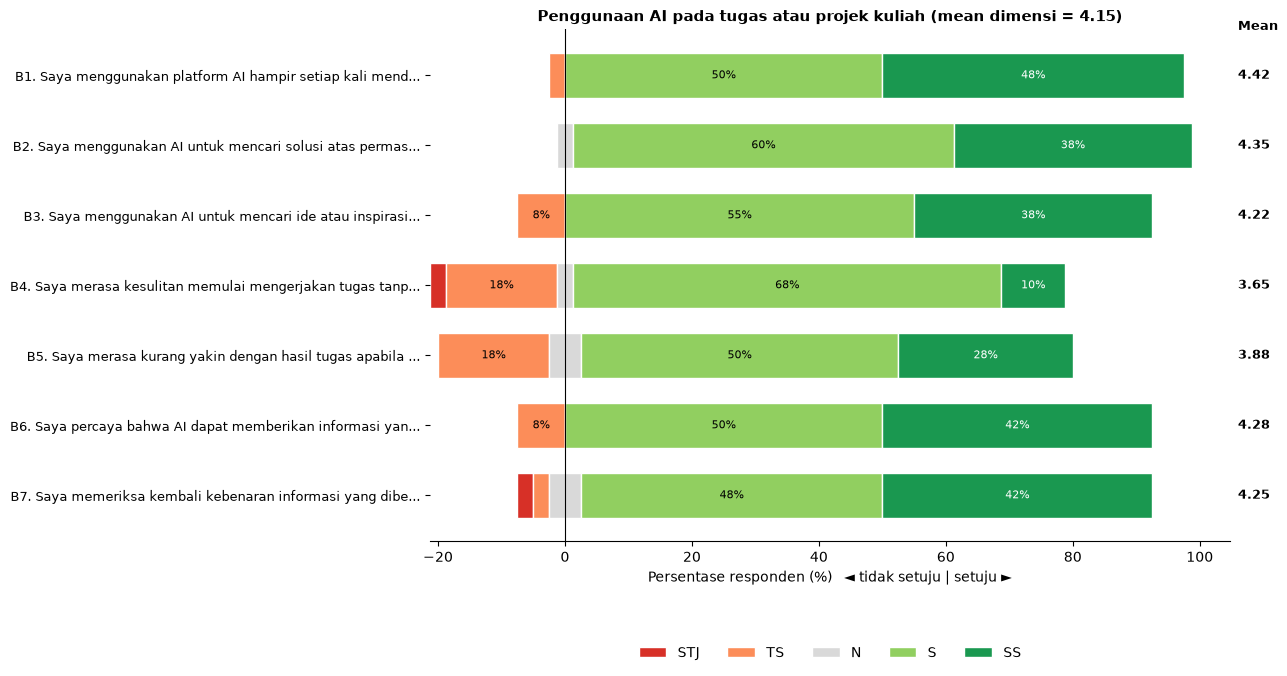

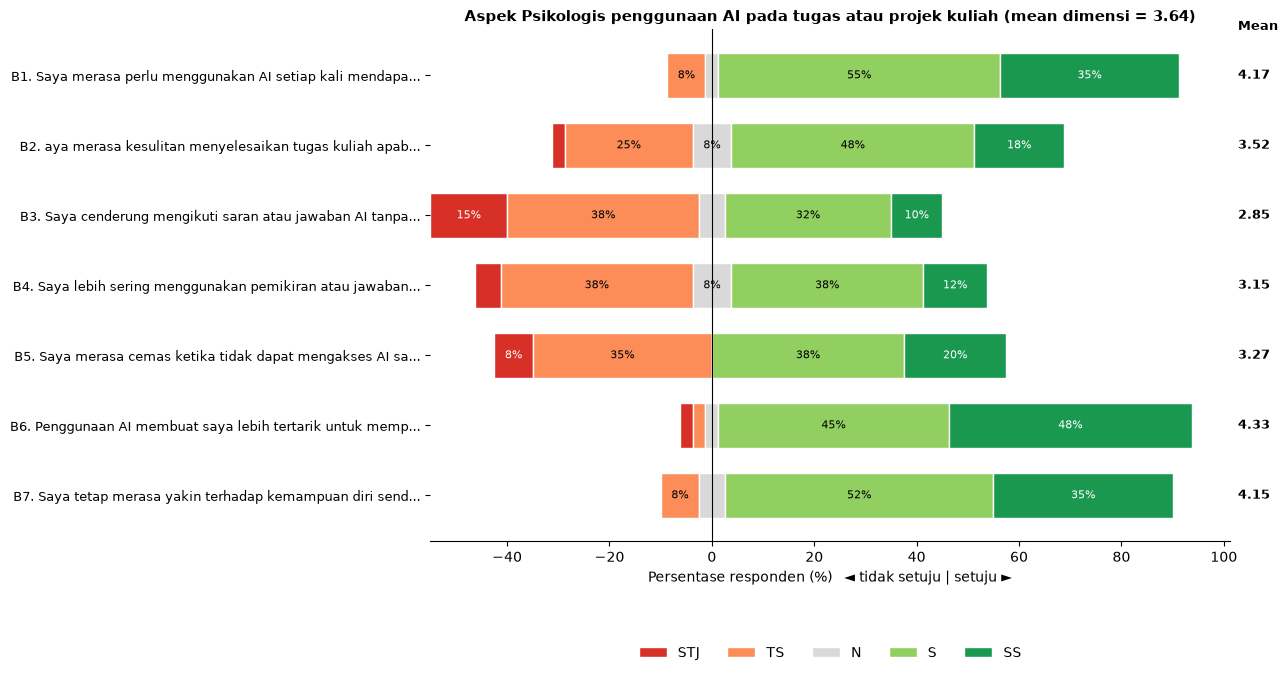

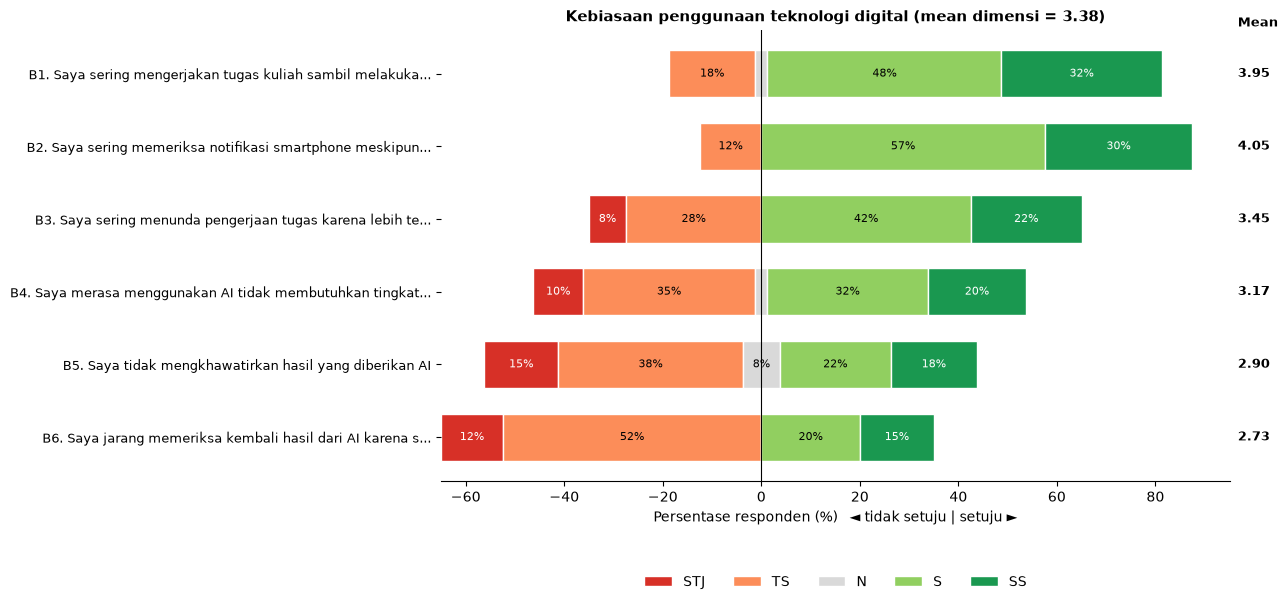

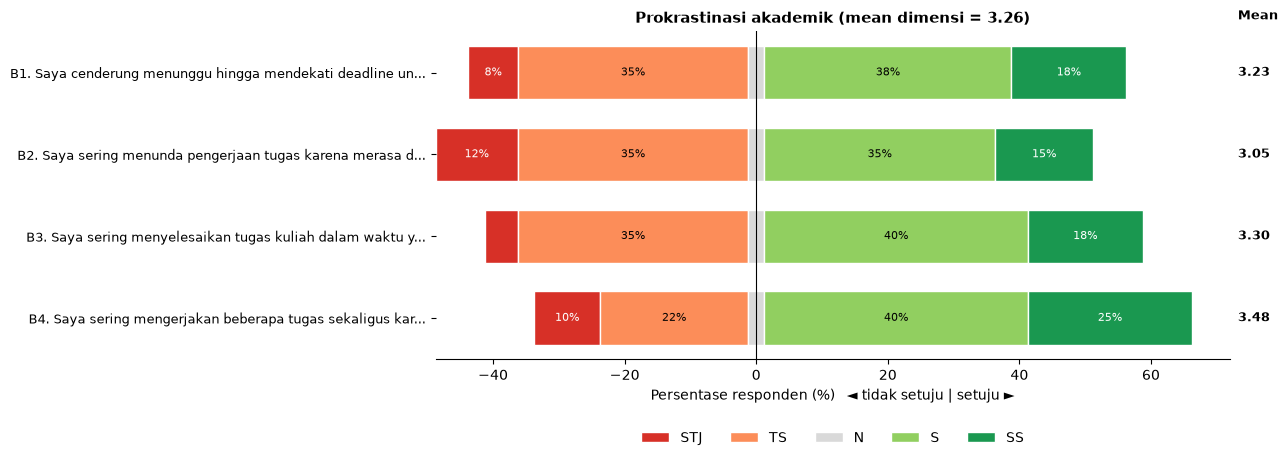

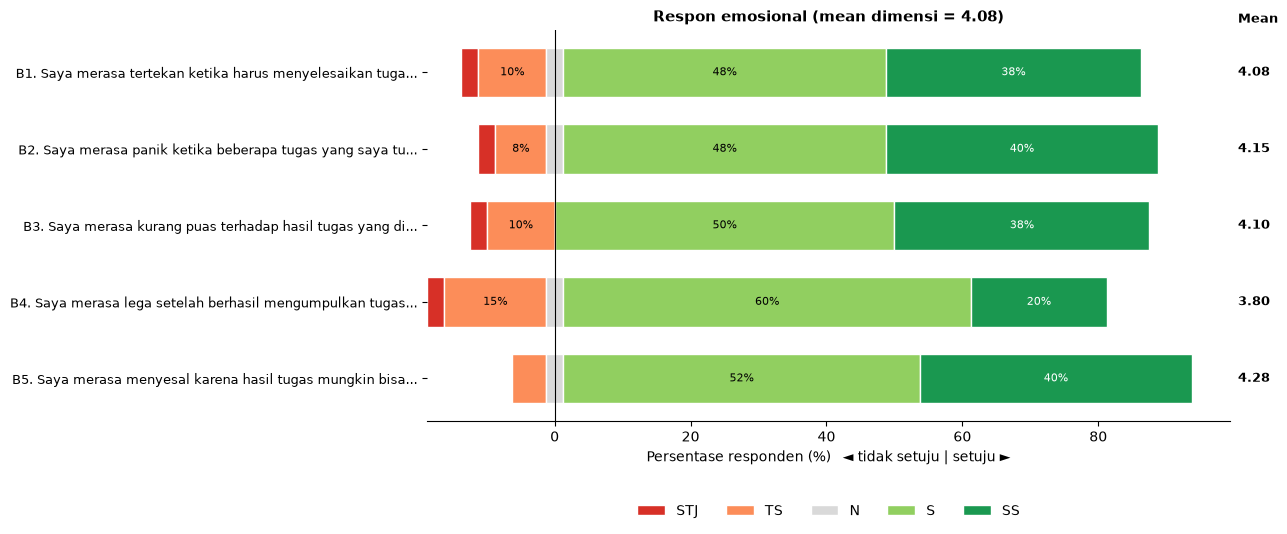

Keterangan kode dimensi:
  D1 = Penggunaan AI pada tugas atau projek kuliah (mean = 4.15)
  D2 = Aspek Psikologis penggunaan AI pada tugas atau projek kuliah (mean = 3.64)
  D3 = Kebiasaan penggunaan teknologi digital (mean = 3.38)
  D4 = Prokrastinasi akademik (mean = 3.26)
  D5 = Respon emosional (mean = 4.08)


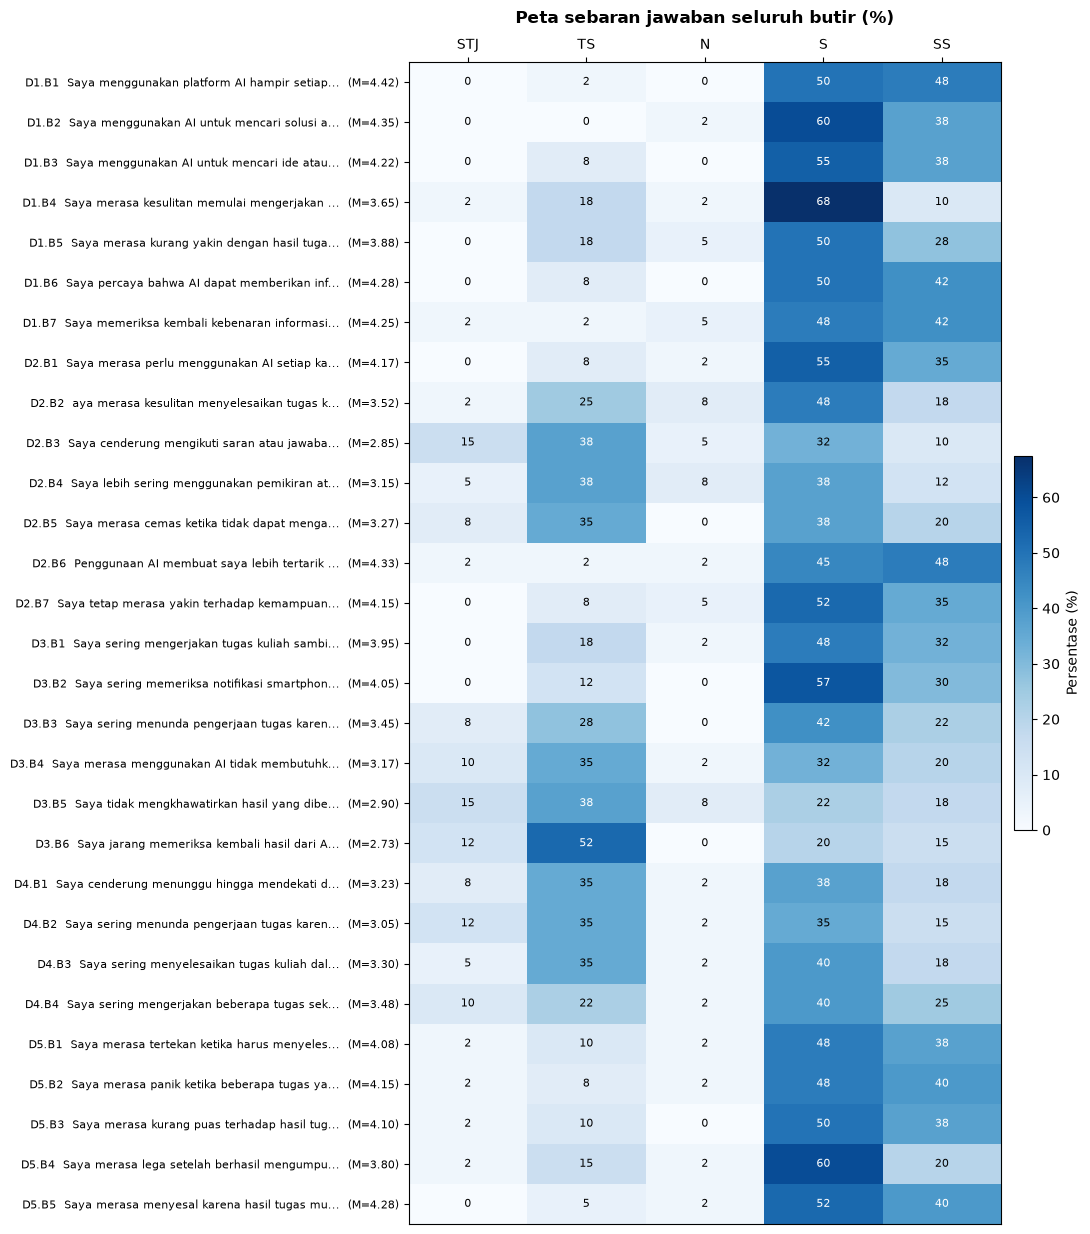

In [82]:
import re
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

urutan = [1, 2, 3, 4, 5]
label = {1: "STJ", 2: "TS", 3: "N", 4: "S", 5: "SS"}
warna = {1: "#d73027", 2: "#fc8d59", 3: "#d9d9d9", 4: "#91cf60", 5: "#1a9850"}
plt.rcParams["font.size"] = 10


def bersih(nama):
    return nama.strip().rstrip(".").strip()


def pendek(kolom, maks=55):
    """Ambil isi pernyataan di dalam [ ] dan potong supaya muat di grafik."""
    m = re.search(r"\[(.*)\]", str(kolom))
    teks = m.group(1) if m else str(kolom)
    return teks if len(teks) <= maks else teks[:maks - 3] + "..."


def persen_butir(kolom):
    hitung = num[kolom].value_counts().reindex(urutan, fill_value=0)
    return hitung / hitung.sum() * 100


def kat_mean(m):
    """Kategori rata-rata skala 1-5 (interval sama, lebar 0,80)."""
    if m <= 1.80:
        return "Sangat rendah"
    elif m <= 2.60:
        return "Rendah"
    elif m <= 3.40:
        return "Sedang"
    elif m <= 4.20:
        return "Tinggi"
    return "Sangat tinggi"


def tampil(nama_file):
    plt.savefig(nama_file, dpi=200, bbox_inches="tight")
    plt.show()


# ============ 0. PERHITUNGAN DASAR ============
gabungan, mean_dim, sd_dim = {}, {}, {}
for nama, daftar in dimensi.items():
    nilai = num[daftar].stack().value_counts().reindex(urutan, fill_value=0)
    gabungan[nama] = nilai / nilai.sum() * 100
    skor = num[daftar].mean(axis=1)
    mean_dim[nama] = skor.mean()
    sd_dim[nama] = skor.std(ddof=1)
gab = pd.DataFrame(gabungan).T

# ============ 1. TABEL RINGKASAN PER DIMENSI ============
baris_tabel = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    skor = x.mean(axis=1)
    semua = x.stack()
    baris_tabel.append({
        "Dimensi": bersih(nama),
        "Jumlah butir": len(daftar),
        "Rata-rata": round(skor.mean(), 3),
        "Median": round(skor.median(), 3),
        "Std. deviasi": round(skor.std(ddof=1), 3),
        "Min": round(skor.min(), 2),
        "Maks": round(skor.max(), 2),
        "% Tidak setuju (1-2)": round((semua <= 2).mean() * 100, 1),
        "% Netral (3)": round((semua == 3).mean() * 100, 1),
        "% Setuju (4-5)": round((semua >= 4).mean() * 100, 1),
        "Kategori rata-rata": kat_mean(skor.mean()),
    })
tabel_distribusi = pd.DataFrame(baris_tabel)
display(tabel_distribusi)

# Tabel rata-rata per butir
baris_butir = []
for nama, daftar in dimensi.items():
    for i, k in enumerate(daftar, 1):
        baris_butir.append({
            "Dimensi": bersih(nama),
            "Butir": f"B{i}",
            "Rata-rata": round(num[k].mean(), 3),
            "Std. deviasi": round(num[k].std(ddof=1), 3),
            "Median": num[k].median(),
            "% Setuju (4-5)": round((num[k] >= 4).mean() * 100, 1),
        })
tabel_mean_butir = pd.DataFrame(baris_butir)
display(tabel_mean_butir)

# ============ 2. RATA-RATA PER DIMENSI (mean ± SD) ============
fig, ax = plt.subplots(figsize=(11, 5.5))
nm = [textwrap.fill(bersih(n), 22) for n in dimensi]
mv = [mean_dim[n] for n in dimensi]
sv = [sd_dim[n] for n in dimensi]
batang = ax.bar(nm, mv, yerr=sv, capsize=5, color="#4c72b0", edgecolor="white")
ax.axhline(3, ls="--", color="gray", lw=1)
ax.text(len(nm) - 0.5, 3.05, "Netral (3)", ha="right", color="gray", fontsize=9)
for rect, m in zip(batang, mv):
    ax.text(rect.get_x() + rect.get_width() / 2, 1.2, f"{m:.2f}",
            ha="center", color="white", weight="bold", fontsize=11)
ax.set_ylim(1, 5.3)
ax.set_ylabel("Rata-rata skor dimensi (1-5)")
ax.set_title("Rata-rata skor per dimensi (batang galat = 1 SD)", fontsize=13, weight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
tampil("gambar_mean_dimensi.png")

# ============ 3. GROUPED BAR: sebaran antar dimensi ============
fig, ax = plt.subplots(figsize=(12, 5.5))
lebar = 0.16
x = np.arange(len(gab))
for j, k in enumerate(urutan):
    batang = ax.bar(x + (j - 2) * lebar, gab[k], lebar,
                    label=label[k], color=warna[k], edgecolor="white")
    for b in batang:
        if b.get_height() >= 3:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5,
                    f"{b.get_height():.0f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([textwrap.fill(bersih(n), 20) + f"\n(mean = {mean_dim[n]:.2f})"
                    for n in gab.index], fontsize=9)
ax.set_ylabel("Persentase jawaban (%)")
ax.set_title("Sebaran jawaban per dimensi", fontsize=13, weight="bold")
ax.legend(title="Jawaban", ncol=5, loc="upper center",
          bbox_to_anchor=(0.5, -0.22), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
tampil("gambar_sebaran_dimensi.png")

# ============ 4. DONUT: komposisi jawaban tiap dimensi ============
jml = len(dimensi)
kol = 3
bar = int(np.ceil(jml / kol))
fig, axes = plt.subplots(bar, kol, figsize=(14, 4.6 * bar))
axes = np.array(axes).flatten()
for ax, (nama, p) in zip(axes, gabungan.items()):
    p = p[p > 0]
    ax.pie(p, colors=[warna[k] for k in p.index], startangle=90, counterclock=False,
           wedgeprops={"width": 0.42, "edgecolor": "white"},
           autopct=lambda v: f"{v:.0f}%" if v >= 4 else "", pctdistance=0.79,
           textprops={"fontsize": 9})
    ax.text(0, 0, f"Mean\n{mean_dim[nama]:.2f}", ha="center", va="center",
            fontsize=12, weight="bold")
    ax.set_title(textwrap.fill(bersih(nama), 30), fontsize=10, weight="bold")
for ax in axes[jml:]:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=warna[k]) for k in urutan]
fig.legend(handles, [label[k] for k in urutan], title="Jawaban",
           loc="lower center", ncol=5, frameon=False)
plt.tight_layout(rect=[0, 0.05, 1, 1])
tampil("gambar_donut_dimensi.png")

# ============ 5. DIVERGING BAR: arah jawaban tiap butir ============
for d, (nama, daftar) in enumerate(dimensi.items(), 1):
    p = pd.DataFrame([persen_butir(k) for k in daftar])
    p.index = [f"B{i}. {pendek(k)}" for i, k in enumerate(daftar, 1)]

    mulai = {
        1: -(p[1] + p[2] + p[3] / 2),
        2: -(p[2] + p[3] / 2),
        3: -p[3] / 2,
        4: p[3] / 2,
        5: p[3] / 2 + p[4],
    }
    fig, ax = plt.subplots(figsize=(13, 0.7 * len(daftar) + 2))
    y = np.arange(len(daftar))[::-1]
    for k in urutan:
        ax.barh(y, p[k], left=mulai[k], color=warna[k], edgecolor="white",
                label=label[k], height=0.65)
        for yi, pk, mk in zip(y, p[k], mulai[k]):
            if pk >= 6:
                ax.text(mk + pk / 2, yi, f"{pk:.0f}%", ha="center", va="center",
                        fontsize=8, color="white" if k in (1, 5) else "black")
    # kolom rata-rata per butir di sisi kanan
    for yi, k in zip(y, daftar):
        ax.text(1.01, yi, f"{num[k].mean():.2f}", transform=ax.get_yaxis_transform(),
                va="center", fontsize=9, weight="bold")
    ax.text(1.01, len(daftar) - 0.35, "Mean", transform=ax.get_yaxis_transform(),
            fontsize=9, weight="bold")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(p.index, fontsize=9)
    ax.set_xlabel("Persentase responden (%)   ◄ tidak setuju | setuju ►")
    ax.set_title(textwrap.fill(f"{bersih(nama)} (mean dimensi = {mean_dim[nama]:.2f})", 90),
                 fontsize=11, weight="bold")
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    tampil(f"gambar_diverging_D{d}.png")

# ============ 6. HEATMAP: semua butir dalam satu gambar ============
baris, nama_baris = [], []
print("Keterangan kode dimensi:")
for d, (nama, daftar) in enumerate(dimensi.items(), 1):
    print(f"  D{d} = {bersih(nama)} (mean = {mean_dim[nama]:.2f})")
    for i, k in enumerate(daftar, 1):
        baris.append(persen_butir(k).values)
        nama_baris.append(f"D{d}.B{i}  {pendek(k, 45)}  (M={num[k].mean():.2f})")
mat = np.array(baris)

fig, ax = plt.subplots(figsize=(11, 0.36 * len(mat) + 2))
im = ax.imshow(mat, cmap="Blues", aspect="auto", vmin=0, vmax=max(60, mat.max()))
ax.set_xticks(range(5))
ax.set_xticklabels([label[k] for k in urutan])
ax.xaxis.tick_top()
ax.set_yticks(range(len(mat)))
ax.set_yticklabels(nama_baris, fontsize=8)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat[i, j]:.0f}", ha="center", va="center", fontsize=8,
                color="white" if mat[i, j] > 35 else "black")
fig.colorbar(im, ax=ax, label="Persentase (%)", fraction=0.03, pad=0.02)
ax.set_title("Peta sebaran jawaban seluruh butir (%)", fontsize=12, weight="bold", pad=28)
plt.tight_layout()
tampil("gambar_heatmap_butir.png")

# Latihan

In [78]:
#1
tdk_valid = tabel_validitas[tabel_validitas["Keterangan"] != "Valid"].copy()
tdk_valid["Isi pernyataan"] = [
    dimensi[d][int(b[1:]) - 1] for d, b in zip(tdk_valid["Dimensi"], tdk_valid["Butir"])
]
pd.set_option("display.max_colwidth", None)
display(tdk_valid[["Dimensi", "Butir", "r hitung", "r tabel", "Corrected r", "Isi pernyataan"]])

,Dimensi,Butir,r hitung,r tabel,Corrected r,Isi pernyataan
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,0.312,-0.061,Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.]
13,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B7,-0.094,0.312,-0.272,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah meskipun menggunakan bantuan AI dalam menyelesaikan tugas kuliah.]


In [75]:
#2
valid_r = (tabel_validitas["r hitung"] > tabel_validitas["r tabel"]).sum()
valid_cr = (tabel_validitas["Corrected r"] >= 0.30).sum()
total = len(tabel_validitas)

print(f"Total butir                  : {total}")
print(f"Valid (r hitung > r tabel)   : {valid_r}")
print(f"Valid (corrected r >= 0,30)  : {valid_cr}")
print(f"Selisih                      : {valid_r - valid_cr} butir")

# Butir yang lolos kriteria pertama tapi gagal kriteria kedua
beda = tabel_validitas[(tabel_validitas["r hitung"] > tabel_validitas["r tabel"]) &
                       (tabel_validitas["Corrected r"] < 0.30)]
display(beda[["Dimensi", "Butir", "r hitung", "Corrected r"]])

Total butir                  : 29
Valid (r hitung > r tabel)   : 27
Valid (corrected r >= 0,30)  : 21
Selisih                      : 6 butir


,Dimensi,Butir,r hitung,Corrected r
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.419,0.222
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.390,0.224
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.506,0.205
12,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B6,0.389,0.208
25,Respon emosional,B2,0.590,0.297
27,Respon emosional,B4,0.413,0.065


In [76]:
#3
# Pilih butir tidak valid dengan corrected r terendah
target = tabel_validitas[tabel_validitas["Keterangan"] != "Valid"].sort_values("Corrected r").iloc[0]
nama_dim, no = target["Dimensi"], int(target["Butir"][1:])
kolom_hapus = dimensi[nama_dim][no - 1]
print(f"Butir dibuang: {nama_dim} - B{no}\n{kolom_hapus}\n")

sebelum = cronbach_alpha(num[dimensi[nama_dim]])
sisa = [k for k in dimensi[nama_dim] if k != kolom_hapus]
sesudah = cronbach_alpha(num[sisa])

print(f"Alpha sebelum: {sebelum:.3f} ({kategori(sebelum)})")
print(f"Alpha sesudah: {sesudah:.3f} ({kategori(sesudah)})")
print(f"Perubahan    : {sesudah - sebelum:+.3f}")

# Jalankan ulang validitas untuk dimensi itu
x = num[sisa]; total = x.sum(axis=1)
display(pd.DataFrame({
    "Butir": [f"B{dimensi[nama_dim].index(k)+1}" for k in sisa],
    "Corrected r": [round(stats.pearsonr(x[k], total - x[k])[0], 3) for k in sisa],
}))

Butir dibuang: Aspek Psikologis penggunaan AI pada tugas atau projek kuliah - B7
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah meskipun menggunakan bantuan AI dalam menyelesaikan tugas kuliah.]

Alpha sebelum: 0.678 (Tidak reliabel)
Alpha sesudah: 0.769 (Reliabel)
Perubahan    : +0.091


,Butir,Corrected r
0,B1,0.477
1,B2,0.591
2,B3,0.637
3,B4,0.464
4,B5,0.678
5,B6,0.250


In [77]:
#4
def validitas_cepat(data):
    n = len(data)
    t = stats.t.ppf(0.975, n - 2)
    r_tab = t / np.sqrt((n - 2) + t**2)
    jml_r, jml_cr = 0, 0
    for nama, daftar in dimensi.items():
        x = data[daftar]; tot = x.sum(axis=1)
        for k in daftar:
            if x[k].nunique() < 2:
                continue
            r = stats.pearsonr(x[k], tot)[0]
            cr = stats.pearsonr(x[k], tot - x[k])[0]
            jml_r += r > r_tab
            jml_cr += cr > r_tab
    return n, r_tab, jml_r, jml_cr

hasil = []
for n in [40, 30, 20, 10]:
    data = num if n == len(num) else num.sample(n, random_state=1)
    n_, rt, a, b = validitas_cepat(data)
    hasil.append({"n": n_, "r tabel": round(rt, 3),
                  "Valid (r hitung)": a, "Valid (corrected r)": b})
display(pd.DataFrame(hasil))

,n,r tabel,Valid (r hitung),Valid (corrected r)
0,40,0.312,27,21
1,30,0.361,24,17
2,20,0.444,23,17
3,10,0.632,18,8
